# STAT 8810 Project — Part 0: Simulated data generation

**Deep learning vs. logistic regression for propensity score estimation and IPW estimation of the ATE.**

This notebook generates and saves **every simulated dataset** used later, focusing on **nonlinear propensity scores**. No model is fit here; later notebooks load these files, fit logistic regression / neural networks for $\hat e(X)$, and plug them into the same IPW estimator.

**Data-generating process (one replication)**

1. Covariates $X = (X_1,\dots,X_{10})$: latent $Z \sim N(0,\Sigma)$ with $\Sigma_{jk} = 0.3^{|j-k|}$; $X_3, X_6, X_9 = \mathbf 1\{Z_j>0\}$ are binary, the rest are continuous $N(0,1)$.
   - $X_1$–$X_4$: **confounders** (affect $A$ and $Y$)
   - $X_5$–$X_7$: **treatment-only** predictors (affect $A$ only)
   - $X_8$–$X_{10}$: **outcome-only** predictors (affect $Y$ only)
2. True propensity score $e(X) = c + (1-2c)\,\mathrm{expit}\{\alpha_0 + \gamma\, \tilde f(X)\}$ with floor $c = 0.01$ (guarantees positivity), where $\tilde f$ is a standardized nonlinear function. Treatment $A \sim \mathrm{Bernoulli}(e(X))$.
3. Potential outcomes $Y(a) = \mu_0(X) + a\,\tau(X) + \varepsilon$, $\varepsilon \sim N(0,1)$ independent of $A$; observed $Y = A\,Y(1) + (1-A)\,Y(0)$.
4. True ATE $= E[\tau(X)] = 1.5$, fixed by design (does not depend on the propensity model).

**Simulation factors**

| Factor | Setting |
|---|---|
| Propensity score (`ps`) | **varied**: `moderate` (quadratics + interactions), `strong` (sin, thresholds, abs, 3-way interaction) |
| Overlap | fixed: `good` ($\gamma=1$, SD of logit = 1) |
| Sample size | $n = 1000$ (main analysis); $n = 2000, 5000$ to study how results change with $n$ |
| Outcome model | fixed: O2 — nonlinear $\mu_0$, heterogeneous $\tau(X)$, true ATE $=1.5$ |
| Replications | $R = 50$ per scenario |

**No separate test set.** Each replication is a single dataset of size $n = 1000$. In the analysis notebooks, $\hat e$ is obtained by **5-fold cross-fitting** (each unit's $\hat e(X_i)$ comes from a model not fit on that unit), and the same out-of-fold $\hat e$ is used for both parts:
- Part 1: $\text{MSE} = \frac1n\sum_i (\hat e(X_i) - e(X_i))^2$ against the stored true $e$;
- Part 2: plugged into the IPW estimator for the ATE.

Neural-network tuning / early stopping uses a validation split inside the training folds.

In [1]:
import json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------- configuration -----------------------------
OUT_DIR    = Path("sim_data")      # all generated files go here
BASE_SEED  = 8810
R          = 50                    # replications per setting
N_LIST     = [1000, 2000, 5000]    # training sample sizes (n = 1000 is the main analysis)
N_CALIB    = 1_000_000             # Monte Carlo draws for calibration / true ATE

P          = 10
RHO        = 0.3                   # AR(1) correlation of latent covariates
BINARY     = [2, 5, 8]             # 0-based columns -> X3, X6, X9 are binary
E_FLOOR    = 0.01                  # e(X) in [0.01, 0.99]  => positivity
TARGET_PT  = 0.5                   # target P(A = 1)

PS_SCENARIOS = ["moderate", "strong"]
OVERLAP      = {"good": 1.0}                   # gamma = SD of the logit (good overlap)

OUT_DIR.mkdir(exist_ok=True)

## 1. Covariates

In [2]:
SIGMA = RHO ** np.abs(np.subtract.outer(np.arange(P), np.arange(P)))
CHOL  = np.linalg.cholesky(SIGMA)

def draw_covariates(n, rng):
    # Return an (n, 10) array; X3, X6, X9 binary (P = 0.5), others N(0, 1).
    Z = rng.standard_normal((n, P)) @ CHOL.T
    Z[:, BINARY] = (Z[:, BINARY] > 0).astype(float)
    return Z

def cols(X):
    # Unpack columns as x1, ..., x10 for readable formulas.
    return [X[:, j] for j in range(X.shape[1])]

## 2. Nonlinear propensity score functions (raw scale)

Only $X_1$–$X_7$ enter the propensity score.

**Moderate** — a logistic model with linear terms plus squares and pairwise interactions (Setoguchi et al. 2008, scenario-G style):
$$f_{\text{mod}} = 0.8x_1 - 0.25x_2 + 0.6x_3 - 0.4x_4 - 0.8x_5 - 0.5x_6 + 0.7x_7 - 0.5x_2^2 + 0.4x_7^2 + 0.5x_1x_3 + 0.5x_2x_4 - 0.4x_5x_6$$

**Strong** — almost no linear signal; periodic, threshold, absolute-value and three-way interaction terms:
$$f_{\text{str}} = 1.2\sin(1.5x_1) + 0.8x_2x_4 - 0.8|x_7| + 1.0\,\mathbf 1\{x_5>0.5\} + 0.8x_3x_6 + 0.6\cos(2x_4) - 0.5x_1x_5x_6$$

In [3]:
def f_moderate(X):
    x1, x2, x3, x4, x5, x6, x7, *_ = cols(X)
    return (0.8*x1 - 0.25*x2 + 0.6*x3 - 0.4*x4 - 0.8*x5 - 0.5*x6 + 0.7*x7
            - 0.5*x2**2 + 0.4*x7**2 + 0.5*x1*x3 + 0.5*x2*x4 - 0.4*x5*x6)

def f_strong(X):
    x1, x2, x3, x4, x5, x6, x7, *_ = cols(X)
    return (1.2*np.sin(1.5*x1) + 0.8*x2*x4 - 0.8*np.abs(x7)
            + 1.0*(x5 > 0.5) + 0.8*x3*x6 + 0.6*np.cos(2*x4) - 0.5*x1*x5*x6)

PS_FUNS = {"moderate": f_moderate, "strong": f_strong}

def expit(z):
    return 1.0 / (1.0 + np.exp(-z))

## 3. Calibration

For each scenario, $f$ is standardized with its Monte Carlo mean and SD, so $\gamma$ equals the SD of the logit and **both scenarios have the same overall strength of selection** — only the *shape* differs. The intercept $\alpha_0$ is then solved by bisection so that $P(A=1) = 0.5$.

The column `linear_R2` is the $R^2$ from regressing the true logit on $X_1,\dots,X_{10}$: the share of the logit a correctly-specified-in-main-effects logistic regression could capture. Lower = harder for logistic regression.

In [4]:
def ps_from_logit(eta):
    return E_FLOOR + (1 - 2*E_FLOOR) * expit(eta)

def solve_alpha0(fstd, gamma, target=TARGET_PT):
    lo, hi = -10.0, 10.0
    for _ in range(100):
        mid = (lo + hi) / 2
        if ps_from_logit(mid + gamma*fstd).mean() < target:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2

rng_cal = np.random.default_rng(np.random.SeedSequence([BASE_SEED, 0]))
X_cal = draw_covariates(N_CALIB, rng_cal)

CALIB, calib_rows = {}, []
for ps in PS_SCENARIOS:
    f = PS_FUNS[ps](X_cal)
    f_mean, f_sd = f.mean(), f.std()
    fstd = (f - f_mean) / f_sd
    for ov, gamma in OVERLAP.items():
        a0 = solve_alpha0(fstd, gamma)
        eta = a0 + gamma*fstd
        e = ps_from_logit(eta)
        Xd = np.column_stack([np.ones(N_CALIB), X_cal])
        beta, *_ = np.linalg.lstsq(Xd, eta, rcond=None)
        r2 = 1 - np.var(eta - Xd @ beta) / np.var(eta)
        CALIB[(ps, ov)] = dict(f_mean=float(f_mean), f_sd=float(f_sd),
                               gamma=gamma, alpha0=float(a0))
        calib_rows.append(dict(
            ps=ps, overlap=ov, gamma=gamma, alpha0=round(a0, 4),
            mean_e=e.mean(), q01=np.quantile(e, .01), q99=np.quantile(e, .99),
            share_e_lt_05=(e < .05).mean(), share_e_gt_95=(e > .95).mean(),
            max_ipw_weight=1/min(e.min(), 1-e.max()),
            linear_R2=r2))

calib_df = pd.DataFrame(calib_rows)
calib_df.round(3)

,ps,overlap,gamma,alpha0,mean_e,q01,q99,share_e_lt_05,share_e_gt_95,max_ipw_weight,linear_R2
0,moderate,good,1.0,-0.003,0.5,0.085,0.909,0.003,0.002,94.580,0.729
1,strong,good,1.0,-0.007,0.5,0.087,0.891,0.002,0.002,96.049,0.255


In [5]:
def true_ps(X, ps, ov):
    c = CALIB[(ps, ov)]
    fstd = (PS_FUNS[ps](X) - c["f_mean"]) / c["f_sd"]
    return ps_from_logit(c["alpha0"] + c["gamma"]*fstd)

## 4. Outcome model (O2) and the true ATE

**O2 (nonlinear, heterogeneous effect)**
$$\mu_0 = x_1 + x_2 + 0.5x_3 + x_4 + x_8 + 0.5x_9 + x_{10} + 0.5x_1x_8 + 0.5x_2x_4, \qquad \tau(X) = 1 + 0.5x_1 + 0.5x_2^2$$

$X_5$–$X_7$ never enter $\mu_0$ or $\tau$. The $x_2x_4$ term is shared with both propensity scores, so failing to capture it in $\hat e$ matters for the ATE.

True ATE $= 1 + 0.5E[X_1] + 0.5E[X_2^2] = 1 + 0 + 0.5 = 1.5$ (checked by Monte Carlo below).

In [6]:
def mu0_O2(X):
    x1, x2, x3, x4, x5, x6, x7, x8, x9, x10 = cols(X)
    return (x1 + x2 + 0.5*x3 + x4 + x8 + 0.5*x9 + x10
            + 0.5*x1*x8 + 0.5*x2*x4)

def tau_O2(X):
    x1, x2, *_ = cols(X)
    return 1 + 0.5*x1 + 0.5*x2**2

TRUE_ATE = 1.5

mc = tau_O2(X_cal)
print(f"O2 true ATE: analytic = 1.5, Monte Carlo = {mc.mean():.4f} "
      f"(MC s.e. {mc.std()/np.sqrt(N_CALIB):.4f})")
del X_cal

O2 true ATE: analytic = 1.5, Monte Carlo = 1.5005 (MC s.e. 0.0009)


## 5. Generate one replication

Every replication has its own seed `SeedSequence([BASE_SEED, ps, overlap, n, r])`, so any single dataset can be regenerated exactly and results don't depend on generation order.

In [7]:
PS_ID = {ps: i+1 for i, ps in enumerate(PS_SCENARIOS)}
OV_ID = {ov: i+1 for i, ov in enumerate(OVERLAP)}

def rng_for(ps, ov, n, r):
    return np.random.default_rng(
        np.random.SeedSequence([BASE_SEED, PS_ID[ps], OV_ID[ov], n, r]))

def simulate_one(n, ps, ov, rng):
    X = draw_covariates(n, rng)
    e = true_ps(X, ps, ov)
    A = rng.binomial(1, e)
    tau = tau_O2(X)
    Y0 = mu0_O2(X) + rng.standard_normal(n)
    Y1 = Y0 + tau
    Y = A*Y1 + (1 - A)*Y0
    return dict(X=X, e=e, A=A, Y=Y, Y0=Y0, Y1=Y1, tau=tau)

# Oracle / naive estimators -- used ONLY as sanity checks of the generated data
def ipw_ht(Y, A, e):
    return np.mean(A*Y/e - (1-A)*Y/(1-e))

def ipw_hajek(Y, A, e):
    w1, w0 = A/e, (1-A)/(1-e)
    return np.sum(w1*Y)/np.sum(w1) - np.sum(w0*Y)/np.sum(w0)

def naive(Y, A):
    return Y[A == 1].mean() - Y[A == 0].mean()

## 6. Generate and save all datasets

File layout (`sim_data/`):

- `train_{ps}_{overlap}_n{n}.npz` — arrays with a leading replication axis: `X (R,n,10)`, `e (R,n)`, `A (R,n)`, `Y (R,n)`, `Y0 (R,n)`, `Y1 (R,n)`, `tau (R,n)`
- `meta.json` — configuration, calibration constants, true ATEs
- `sanity_summary.csv` — per-replication treated share, sample ATE, naive and oracle IPW estimates

Estimators may only use `X`, `A`, `Y`. The ground-truth arrays `e`, `Y0`, `Y1`, `tau` are for evaluation.

In [8]:
t0 = time.time()
summary_rows = []

for ps in PS_SCENARIOS:
    for ov in OVERLAP:
        # ---- R replications, one dataset each ----
        for n in N_LIST:
            reps = [simulate_one(n, ps, ov, rng_for(ps, ov, n, r)) for r in range(R)]
            stack = lambda k, dt: np.stack([d[k] for d in reps]).astype(dt)
            np.savez_compressed(OUT_DIR / f"train_{ps}_{ov}_n{n}.npz",
                                X=stack("X", np.float32), e=stack("e", np.float64),
                                A=stack("A", np.int8), Y=stack("Y", np.float64),
                                Y0=stack("Y0", np.float64), Y1=stack("Y1", np.float64),
                                tau=stack("tau", np.float64))
            for r, d in enumerate(reps):
                summary_rows.append(dict(
                    ps=ps, overlap=ov, n=n, rep=r,
                    treated_share=d["A"].mean(),
                    min_e=d["e"].min(), max_e=d["e"].max(),
                    sate=d["tau"].mean(),
                    naive=naive(d["Y"], d["A"]),
                    oracle_ht=ipw_ht(d["Y"], d["A"], d["e"]),
                    oracle_hajek=ipw_hajek(d["Y"], d["A"], d["e"])))
            print(f"saved train_{ps}_{ov}_n{n}.npz   ({time.time()-t0:.0f}s)")

summary = pd.DataFrame(summary_rows)
summary.to_csv(OUT_DIR / "sanity_summary.csv", index=False)

meta = dict(base_seed=BASE_SEED, R=R, n_list=N_LIST, p=P, rho=RHO,
            binary_columns_1based=[j+1 for j in BINARY], e_floor=E_FLOOR,
            target_treated_share=TARGET_PT, outcome_model="O2", true_ate=TRUE_ATE,
            calibration={f"{ps}_{ov}": v for (ps, ov), v in CALIB.items()},
            covariate_roles=dict(confounders=[1, 2, 3, 4], treatment_only=[5, 6, 7],
                                 outcome_only=[8, 9, 10]))
(OUT_DIR / "meta.json").write_text(json.dumps(meta, indent=2))

total_mb = sum(f.stat().st_size for f in OUT_DIR.iterdir()) / 1e6
print(f"done in {time.time()-t0:.0f}s, {total_mb:.0f} MB in {OUT_DIR}/")

saved train_moderate_good_n1000.npz   (0s)
saved train_strong_good_n1000.npz   (0s)
done in 0s, 7 MB in sim_data/


## 7. Sanity checks

With the **true** $e(X)$, IPW should be (nearly) unbiased for the true ATE, while the naive difference in means should be clearly biased — confirming there is real confounding to remove.

In [9]:
main = summary[summary.n == N_LIST[0]]     # checks for the main analysis size, n = 1000
rows = []
for ps, g in main.groupby("ps", sort=False):
    for est in ["naive", "oracle_ht", "oracle_hajek"]:
        v = g[est]
        rows.append(dict(ps=ps, estimator=est, mean=v.mean(),
                         bias=v.mean() - TRUE_ATE, sd=v.std(),
                         rmse=np.sqrt(np.mean((v - TRUE_ATE)**2)),
                         mc_se_bias=v.std() / np.sqrt(len(v))))
check_df = pd.DataFrame(rows)
print(f"true ATE = {TRUE_ATE};  mean treated share = {main.treated_share.mean():.3f};  "
      f"mean sample ATE = {main.sate.mean():.3f}")
check_df.round(3)

true ATE = 1.5;  mean treated share = 0.500;  mean sample ATE = 1.503


,ps,estimator,mean,bias,sd,rmse,mc_se_bias
0,moderate,naive,1.831,0.331,0.221,0.396,0.031
1,moderate,oracle_ht,1.474,-0.026,0.278,0.276,0.039
2,moderate,oracle_hajek,1.469,-0.031,0.254,0.254,0.036
3,strong,naive,2.353,0.853,0.181,0.872,0.026
4,strong,oracle_ht,1.469,-0.031,0.243,0.242,0.034
5,strong,oracle_hajek,1.474,-0.026,0.233,0.232,0.033


## 8. Visualizing the simulated data

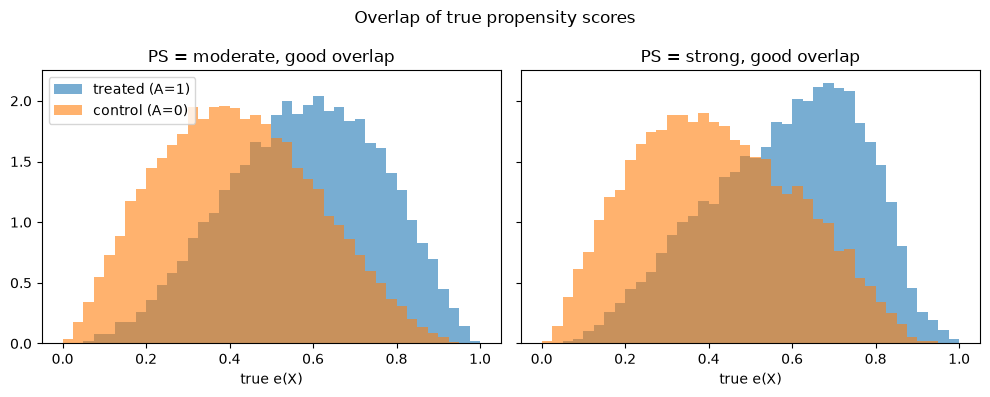

In [10]:
# (a) Overlap: distribution of the true propensity score by treatment group
#     (pooled over all R replications)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
bins = np.linspace(0, 1, 41)
for ax, ps in zip(axes, PS_SCENARIOS):
    d = np.load(OUT_DIR / f"train_{ps}_good_n{N_LIST[0]}.npz")
    e_all, A_all = d["e"].ravel(), d["A"].ravel()
    ax.hist(e_all[A_all == 1], bins=bins, alpha=.6, density=True, label="treated (A=1)")
    ax.hist(e_all[A_all == 0], bins=bins, alpha=.6, density=True, label="control (A=0)")
    ax.set_title(f"PS = {ps}, good overlap")
    ax.set_xlabel("true e(X)")
axes[0].legend()
fig.suptitle("Overlap of true propensity scores")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_overlap.png", dpi=150)
plt.show()

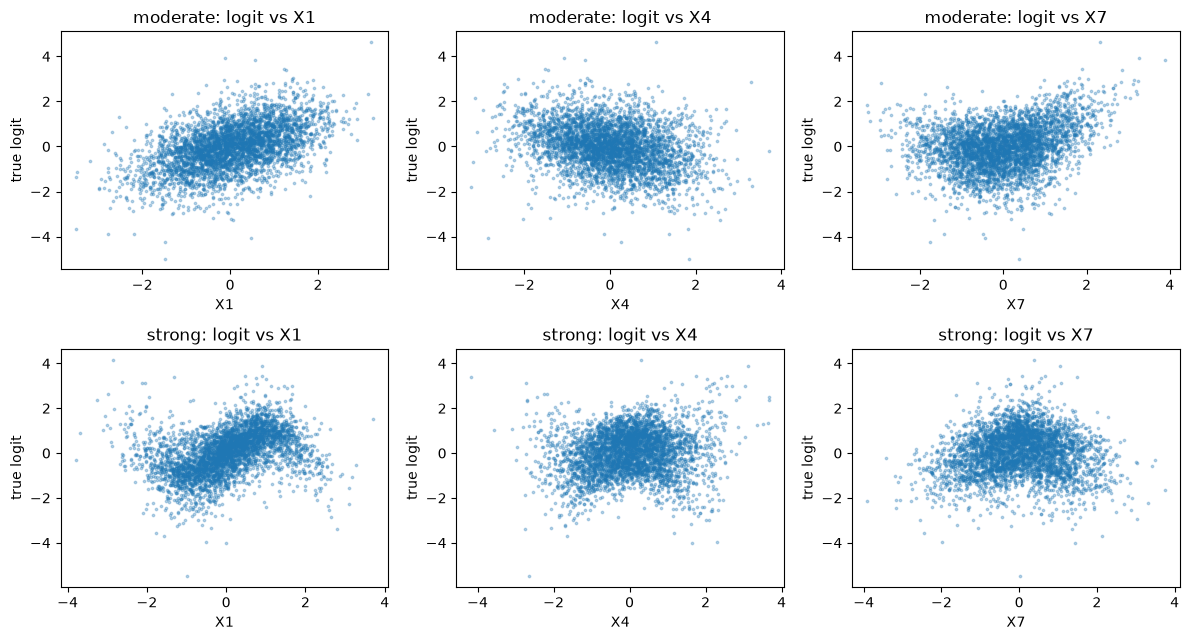

In [11]:
# (b) Shape of the nonlinearity: true logit vs. single confounders (other covariates vary)
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for i, ps in enumerate(PS_SCENARIOS):
    d = np.load(OUT_DIR / f"train_{ps}_good_n{N_LIST[0]}.npz")
    X = d["X"].reshape(-1, P)[:4000]
    e = d["e"].ravel()[:4000]
    logit = np.log((e - E_FLOOR) / (1 - E_FLOOR - e))
    for j, (k, name) in enumerate([(0, "X1"), (3, "X4"), (6, "X7")]):
        ax = axes[i, j]
        ax.scatter(X[:, k], logit, s=3, alpha=.3)
        ax.set_xlabel(name); ax.set_ylabel("true logit")
        ax.set_title(f"{ps}: logit vs {name}")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_ps_shape.png", dpi=150)
plt.show()

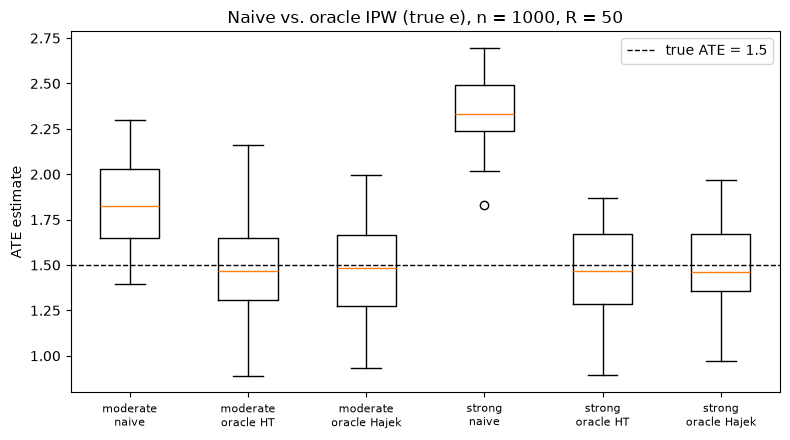

In [12]:
# (c) Naive vs. oracle IPW estimates across the R replications
fig, ax = plt.subplots(figsize=(8, 4.5))
data, labels = [], []
for ps in PS_SCENARIOS:
    g = summary[(summary.ps == ps) & (summary.n == N_LIST[0])]
    data += [g["naive"], g["oracle_ht"], g["oracle_hajek"]]
    labels += [f"{ps}\nnaive", f"{ps}\noracle HT", f"{ps}\noracle Hajek"]
ax.boxplot(data)
ax.set_xticks(range(1, len(labels)+1), labels, fontsize=8)
ax.axhline(TRUE_ATE, color="k", ls="--", lw=1, label=f"true ATE = {TRUE_ATE}")
ax.set_ylabel("ATE estimate")
ax.set_title(f"Naive vs. oracle IPW (true e), n = {N_LIST[0]}, R = {R}")
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_naive_vs_oracle.png", dpi=150)
plt.show()

## 9. Loader for the analysis notebooks

Copy this into later notebooks.

In [13]:
def load_setting(ps, overlap="good", n=1000, data_dir="sim_data"):
    # Returns a dict of arrays with a leading replication axis, shape (R, n, ...).
    return dict(np.load(Path(data_dir) / f"train_{ps}_{overlap}_n{n}.npz"))

data = load_setting("strong")
r = 0
X, A, Y = data["X"][r].astype(float), data["A"][r], data["Y"][r]   # what estimators may see
e_true  = data["e"][r]                                              # ground truth, evaluation only
print({k: v.shape for k, v in data.items()})

{'X': (50, 1000, 10), 'e': (50, 1000), 'A': (50, 1000), 'Y': (50, 1000), 'Y0': (50, 1000), 'Y1': (50, 1000), 'tau': (50, 1000)}
